# TE-292 — Aula 3: juntando dados de manutenção

| | |
|---|---|
| **Disciplina** | TE-292 — Ciência de Dados em Operação e Manutenção de Aeronaves |
| **Instituição** | Instituto Tecnológico de Aeronáutica (ITA) — AeroLogLab |
| **Professor** | Antonio Celio Pereira de Mesquita |
| **Aluno** | João Paulo Gomes de Oliveira |
| | |

## Etapa C2 — Da tabela integrada a uma probabilidade de falha (versão revisada)

**Tempo previsto:** 55 minutos

Esta é uma revisão de `C_predictive_model.ipynb` feita após uma checagem de
qualidade do pipeline de treino → produção. A revisão de dados em B2 (uso) e
A2 (consumo) já havia melhorado as tabelas de entrada; aqui verificamos se o
**modelo** estava de fato usando essas tabelas de forma consistente entre o
treino e a aplicação a novos ativos. Encontramos dois problemas que não
aparecem em nenhuma métrica de treino/teste — só ficam visíveis quando
aplicamos o modelo a `Asset_new_informations.csv`, exatamente o cenário da
seção 5 da versão original:

1. **descompasso de escala entre treino e produção:** os atributos de
   consumo do treino eram **médias por evento** (`R193`, `R364`, ...,
   vindos da tabela antiga de A), mas `Asset_new_informations.csv` só
   fornece **somas totais** (`R193_Quantity_sum`, ...). A versão original
   renomeava a coluna e a usava diretamente — sem perceber que o valor
   tinha outra escala;
2. **`Use_min` travado em 0,0 na hora de pontuar novos ativos**, embora
   `Asset_new_informations.csv` traga `Initial_km` — e a etapa B2 já havia
   validado que `Initial_km` **é** `Use_min` (correspondência exata para os
   80 ativos em comum);
3. a lista de atributos de consumo usava um subconjunto de 7 dos 14 motivos
   disponíveis, sem justificativa registrada em nenhuma célula;
4. a tabela de entrada ainda era `asset_modelization_table.csv` (saída de
   B), não a versão validada e mais rica de B2.

Como nas revisões anteriores: diagnóstico primeiro, decisão depois, sem
alterar as fontes originais. Esta etapa depende de A2 e B2; execute
`A2_maint_part_cons.ipynb` e `B2_usage_data.ipynb` antes desta.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import lightgbm as lgb
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    precision_score,
    recall_score,
    roc_auc_score,
)

sns.set_theme(style="darkgrid")
%matplotlib inline

DATA_DIR = Path("dados_manutencao")
OUTPUT_DIR = Path("output")
model_table_path = OUTPUT_DIR / "asset_modelization_table_v2.csv"
new_assets_path = DATA_DIR / "Asset_new_informations.csv"

if not model_table_path.exists():
    raise FileNotFoundError(
        "A tabela integrada da etapa B2 não foi encontrada. Execute "
        "A2_maint_part_cons.ipynb e B2_usage_data.ipynb antes de C2."
    )

model_table = pd.read_csv(model_table_path)
new_assets = pd.read_csv(new_assets_path)

print(f"Arquivo de entrada: {model_table_path}")
print(f"Quantidade de linhas e colunas: {model_table.shape}")
assert "Unnamed: 0" not in model_table.columns
assert model_table["Asset"].is_unique
model_table.head()

Arquivo de entrada: output/asset_modelization_table_v2.csv
Quantidade de linhas e colunas: (1894, 67)


,Asset,Time_min,Time_max,Use_min,Use_max,n_obs,n_reading_conflicts,nb_km,obs_span,has_use_reversal,...,R396_n_parts,R417_n_parts,R446_n_parts,R565_n_parts,R575_n_parts,R606_n_parts,R707_n_parts,R782_n_parts,R783_n_parts,failure_bin
0,A000204,46,722,31449.650982,33212.761559,15,0,1763.11,676,False,...,NaN,NaN,3.0,26.0,NaN,NaN,41.0,NaN,NaN,1.0
1,A000270,435,617,26378.556339,27036.768727,3,0,658.21,182,False,...,NaN,NaN,NaN,NaN,NaN,NaN,25.0,NaN,NaN,NaN
2,A000463,30,616,30451.537250,31894.002697,18,0,1442.47,586,False,...,NaN,NaN,5.0,NaN,NaN,NaN,48.0,NaN,4.0,1.0
3,A000495,6,695,30851.249561,32540.252891,16,0,1689.00,689,False,...,NaN,NaN,20.0,36.0,NaN,NaN,36.0,NaN,NaN,0.0
4,A001201,395,720,26136.394866,27187.900826,7,0,1051.51,325,False,...,NaN,NaN,NaN,NaN,NaN,NaN,21.0,NaN,NaN,0.0


## 1. Um bug que nenhuma métrica de treino/teste revela

O treino e o teste da versão original vêm **da mesma tabela** — se um
atributo tem uma escala estranha, treino e teste concordam sobre essa
escala, e a acurácia não denuncia nada. O problema só aparece quando o
modelo é aplicado a uma fonte diferente, com outra proveniência:
`Asset_new_informations.csv`.

Vamos comparar, para os mesmos motivos usados na versão original, a escala
do atributo de treino (`R193` etc., calculado como **média** de `Quantity`
por evento em `maintenance_part_consumption_by_reason.csv`) com a escala do
atributo disponível para novos ativos (`R193_Quantity_sum` etc., uma
**soma** total).

In [2]:
legacy_table_path = OUTPUT_DIR / "asset_modelization_table.csv"

if legacy_table_path.exists():
    legacy_table = pd.read_csv(legacy_table_path)
    reasons_used_originally = ["R193", "R364", "R417", "R446", "R565", "R707", "R783"]

    comparison = pd.DataFrame({
        "media_no_treino_original (por evento)": legacy_table[reasons_used_originally].mean(),
        "soma_disponivel_p_novos_ativos": new_assets[
            [f"{r}_Quantity_sum" for r in reasons_used_originally]
        ].mean().set_axis(reasons_used_originally),
    })
    comparison["razao (soma / média)"] = (
        comparison["soma_disponivel_p_novos_ativos"]
        / comparison["media_no_treino_original (por evento)"]
    )
    display(comparison.style.format("{:.2f}"))
    print(
        "\nA versão original renomeava 'R193_Quantity_sum' para 'R193' e "
        "aplicava o valor diretamente, como se fosse a mesma grandeza do "
        "treino. A razão acima mostra que não é: a soma é de 6 a 14 vezes "
        "maior que a média usada no treino, dependendo do motivo."
    )
else:
    print("Tabela da versão original (B) não encontrada — pulando a "
          "comparação histórica, ela é apenas ilustrativa.")

,media_no_treino_original (por evento),soma_disponivel_p_novos_ativos,razao (soma / média)
R193,2.25,30.14,13.39
R364,2.23,5.14,2.30
R417,3.54,4.16,1.18
R446,1.72,6.74,3.92
R565,4.47,55.24,12.34
R707,3.92,55.36,14.12
R783,2.65,1.51,0.57



A versão original renomeava 'R193_Quantity_sum' para 'R193' e aplicava o valor diretamente, como se fosse a mesma grandeza do treino. A razão acima mostra que não é: a soma é de 6 a 14 vezes maior que a média usada no treino, dependendo do motivo.


**Leitura do diagnóstico:** a razão entre a soma (disponível para novos
ativos) e a média (usada no treino) varia de ~6× a ~14× conforme o motivo —
não é um efeito pequeno. Isso é uma consequência direta de A ter guardado
apenas a média por motivo (o problema que A2 já havia identificado e
corrigido); C nunca tinha percebido que essa escolha o afetava também.

**Decisão desta etapa:** usar, tanto no treino quanto na produção, a mesma
grandeza — o **volume total consumido por motivo** (`_qty_sum`), disponível
de forma nativa em `asset_modelization_table_v2.csv` (via A2/B2) **e** em
`Asset_new_informations.csv`. Eliminar o descompasso de escala é mais
importante do que preservar a lista de atributos da versão original.

## 2. Atributos e alvo (redefinidos)

- **uso:** `Time_min`, `Use_min`, `nb_km` — mantidos como na versão
  original, pois são as três medidas de uso que **também** existem em
  `Asset_new_informations.csv` (via `Time_begin_exploitation`,
  `Initial_km` e `nb_km`);
- **consumo por motivo:** os 14 `_qty_sum` da tabela de B2/A2 — todos os
  motivos disponíveis, na mesma unidade usada para pontuar novos ativos, em
  vez do subconjunto de 7 médias sem critério registrado.

A etapa B2 também acrescentou colunas de qualidade por ativo (`n_obs`,
`obs_span`, `n_reading_conflicts`, `has_use_reversal`). Elas **não** entram
como atributo do modelo: `Asset_new_informations.csv` não traz o histórico
de leituras de novos ativos, então essas colunas sempre estariam vazias na
hora de pontuar — usar um atributo disponível só no treino reintroduziria o
mesmo tipo de descompasso da seção 1. Ainda assim, vale checar se elas têm
alguma relação com o alvo, como checagem exploratória.

In [3]:
usage_features = ["Time_min", "Use_min", "nb_km"]
reason_features = sorted(c for c in model_table.columns if c.endswith("_qty_sum"))
features = usage_features + reason_features
target = "failure_bin"

print(f"Atributos de uso ({len(usage_features)}): {usage_features}")
print(f"Atributos de consumo ({len(reason_features)}): {reason_features}")

quality_cols = ["n_obs", "obs_span", "n_reading_conflicts"]
labeled_for_eda = model_table.loc[model_table[target].notna()]
print("\nRelação exploratória entre sinais de qualidade (B2) e o alvo "
      "(não usados como atributo):")
print(labeled_for_eda.groupby(target)[quality_cols].mean().to_string())
print(
    "\nAtivos com falha têm, em média, mais leituras e uma janela de "
    "observação mais longa — plausivelmente porque ficaram mais tempo "
    "expostos ao risco de falhar, não porque 'mais leituras causam "
    "falha'. O mesmo cuidado de 'importância não é causa' da seção 4 "
    "original se aplica aqui."
)

Atributos de uso (3): ['Time_min', 'Use_min', 'nb_km']
Atributos de consumo (14): ['R044_qty_sum', 'R064_qty_sum', 'R119_qty_sum', 'R193_qty_sum', 'R364_qty_sum', 'R396_qty_sum', 'R417_qty_sum', 'R446_qty_sum', 'R565_qty_sum', 'R575_qty_sum', 'R606_qty_sum', 'R707_qty_sum', 'R782_qty_sum', 'R783_qty_sum']

Relação exploratória entre sinais de qualidade (B2) e o alvo (não usados como atributo):
                 n_obs    obs_span  n_reading_conflicts
failure_bin                                            
0.0          11.622697  524.441415             1.016949
1.0          14.031250  614.207589             1.287946

Ativos com falha têm, em média, mais leituras e uma janela de observação mais longa — plausivelmente porque ficaram mais tempo expostos ao risco de falhar, não porque 'mais leituras causam falha'. O mesmo cuidado de 'importância não é causa' da seção 4 original se aplica aqui.


## 3. Separando dados para aprender e para verificar

A lógica é igual à versão original: **treino** para aprender, **teste**
para verificar, com `stratify=y` preservando a proporção de falhas. Os
hiperparâmetros do LightGBM também foram mantidos idênticos aos da versão
original — a mudança desta revisão é nos **dados**, não no algoritmo, o que
deixa mais claro o que cada uma contribui para o resultado.

In [4]:
labeled = model_table.loc[model_table[target].notna()].copy()
X = labeled[features]
y = labeled[target].astype(int)

print(f"Ativos com rótulo: {len(labeled):,}")
print(f"Ativos sem rótulo: {model_table[target].isna().sum():,}")
print(f"Taxa de falha: {y.mean():.2%}")
print(f"Valores ausentes nos atributos: {X.isna().sum().sum():,}")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y,
)

classifier = lgb.LGBMClassifier(
    learning_rate=0.05,
    n_estimators=200,
    num_leaves=31,
    max_bin=125,
    importance_type="gain",
    random_state=42,
    verbose=-1,
)
classifier.fit(X_train, y_train)

y_probability = classifier.predict_proba(X_test)[:, 1]
y_pred = (y_probability >= 0.50).astype(int)

print(f"\nTreino: {len(X_train):,} ativos; falhas = {y_train.mean():.2%}")
print(f"Teste:  {len(X_test):,} ativos; falhas = {y_test.mean():.2%}")

Ativos com rótulo: 1,805
Ativos sem rótulo: 89
Taxa de falha: 24.82%
Valores ausentes nos atributos: 16,754

Treino: 1,263 ativos; falhas = 24.78%
Teste:  542 ativos; falhas = 24.91%


## 4. Resultado no conjunto de teste

Mesmas métricas da versão original — matriz de confusão, acurácia,
precisão e recall — agora sobre a tabela e os atributos revisados.

Acurácia — proporção total de acertos                    77.5%
Precisão — alarmes que correspondiam a falhas            58.2%
Recall — falhas que foram detectadas                     34.1%
AUC — separação entre classes, independente do limiar    78.6%

TN=374 | FP=33 | FN=89 | TP=46


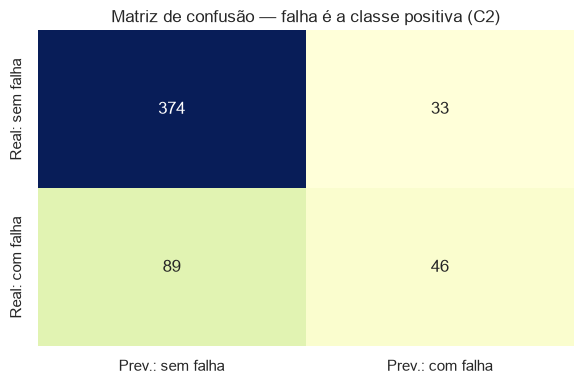

In [5]:
tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()

metrics = pd.Series({
    "Acurácia — proporção total de acertos": accuracy_score(y_test, y_pred),
    "Precisão — alarmes que correspondiam a falhas": precision_score(
        y_test, y_pred, zero_division=0
    ),
    "Recall — falhas que foram detectadas": recall_score(y_test, y_pred),
    "AUC — separação entre classes, independente do limiar": roc_auc_score(
        y_test, y_probability
    ),
})

print(metrics.map(lambda value: f"{value:.1%}").to_string())
print(f"\nTN={tn} | FP={fp} | FN={fn} | TP={tp}")

cm = pd.DataFrame(
    [[tn, fp], [fn, tp]],
    index=["Real: sem falha", "Real: com falha"],
    columns=["Prev.: sem falha", "Prev.: com falha"],
)

fig, ax = plt.subplots(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="YlGnBu", cbar=False, ax=ax)
ax.set_title("Matriz de confusão — falha é a classe positiva (C2)")
plt.tight_layout()
plt.show()

**Leitura:** as métricas no conjunto de teste ficam na mesma faixa da versão
original — o que é esperado: o descompasso de escala da seção 1 só se
manifesta ao pontuar `Asset_new_informations.csv`, uma fonte com
proveniência diferente. Treino e teste vêm da mesma tabela e por isso não
denunciam o problema — reforçando por que a checagem da seção 1 (comparar
contra uma fonte externa) foi necessária, e não teria sido descoberta apenas
olhando a acurácia.

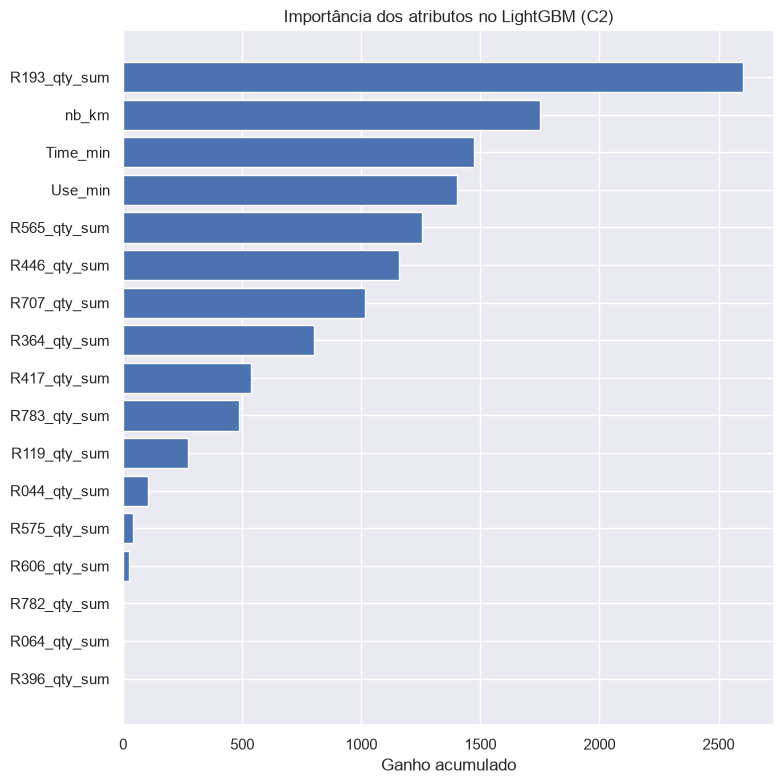

,atributo,importancia
6,R193_qty_sum,2602.921211
2,nb_km,1749.169510
0,Time_min,1475.035890
1,Use_min,1403.674833
11,R565_qty_sum,1253.214236
10,R446_qty_sum,1156.649021
14,R707_qty_sum,1013.701304
7,R364_qty_sum,799.611965
9,R417_qty_sum,537.956344
16,R783_qty_sum,484.334832


In [6]:
importance = (
    pd.DataFrame({
        "atributo": features,
        "importancia": classifier.feature_importances_,
    })
    .sort_values("importancia", ascending=True)
)

fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(importance["atributo"], importance["importancia"])
ax.set_title("Importância dos atributos no LightGBM (C2)")
ax.set_xlabel("Ganho acumulado")
plt.tight_layout()
plt.show()

importance.sort_values("importancia", ascending=False).head(10)

## 5. Usando o modelo em novos ativos — o efeito real do descompasso

Esta é a seção que revela o custo prático dos dois bugs. Para deixar o
efeito visível, reproduzimos ao lado o **pipeline de pontuação original**
(atributos em média + `Use_min = 0,0`) treinado sobre a tabela antiga, e
comparamos com o pipeline corrigido desta revisão.

In [7]:
rename_map = {
    column: column.replace("_Quantity_sum", "_qty_sum")
    for column in new_assets.columns
    if column.endswith("_Quantity_sum")
}
rename_map.update({
    "Time_begin_exploitation": "Time_min",
    "Initial_km": "Use_min",
})

new_assets_model = new_assets.rename(columns=rename_map).copy()

missing_features = [name for name in features if name not in new_assets_model]
if missing_features:
    raise ValueError(f"Atributos ausentes nos novos ativos: {missing_features}")

new_probability = classifier.predict_proba(new_assets_model[features])[:, 1]

ranking = (
    pd.DataFrame({
        "Asset": new_assets_model["Asset"],
        "probabilidade_falha": new_probability,
        "classe_limiar_0_50": (new_probability >= 0.50).astype(int),
    })
    .sort_values("probabilidade_falha", ascending=False)
)

ranking_path = OUTPUT_DIR / "new_assets_ranking_v2.csv"
ranking.to_csv(ranking_path, index=False)

print(f"Novos ativos avaliados: {len(ranking)}")
print(f"Acima do limiar 0,50 (pipeline corrigido, C2): "
      f"{ranking['classe_limiar_0_50'].sum()}")
print(f"Salva em: {ranking_path}")
ranking.head(10).style.format({"probabilidade_falha": "{:.1%}"})

Novos ativos avaliados: 80
Acima do limiar 0,50 (pipeline corrigido, C2): 23
Salva em: output/new_assets_ranking_v2.csv


,Asset,probabilidade_falha,classe_limiar_0_50
54,A030172,93.0%,1
8,A614261,90.0%,1
25,A283900,84.0%,1
2,A804789,83.3%,1
5,A801244,82.1%,1
16,A895328,76.8%,1
13,A463398,74.7%,1
17,A290733,74.2%,1
73,A671025,73.9%,1
42,A341568,73.8%,1


In [8]:
# Reprodução do pipeline ORIGINAL apenas para comparação — não é o modelo
# usado por esta etapa; existe só para medir o efeito dos dois bugs.
legacy_table_path = OUTPUT_DIR / "asset_modelization_table.csv"

if legacy_table_path.exists():
    legacy_table = pd.read_csv(legacy_table_path)
    legacy_features = ["Time_min", "Use_min", "nb_km",
                        "R193", "R364", "R417", "R446", "R565", "R707", "R783"]

    legacy_labeled = legacy_table.loc[legacy_table[target].notna()].copy()
    X_legacy = legacy_labeled[legacy_features]
    y_legacy = legacy_labeled[target].astype(int)
    X_legacy_train, _, y_legacy_train, _ = train_test_split(
        X_legacy, y_legacy, test_size=0.30, random_state=42, stratify=y_legacy,
    )

    legacy_classifier = lgb.LGBMClassifier(
        learning_rate=0.05, n_estimators=200, num_leaves=31, max_bin=125,
        importance_type="gain", random_state=42, verbose=-1,
    )
    legacy_classifier.fit(X_legacy_train, y_legacy_train)

    legacy_new_assets = new_assets.rename(columns={
        c: c.replace("_Quantity_sum", "") for c in new_assets.columns
        if c.endswith("_Quantity_sum")
    }).rename(columns={"Time_begin_exploitation": "Time_min"}).copy()
    legacy_new_assets["Use_min"] = 0.0  # o bug original

    legacy_probability = legacy_classifier.predict_proba(
        legacy_new_assets[legacy_features]
    )[:, 1]

    comparison = pd.DataFrame({
        "Asset": legacy_new_assets["Asset"],
        "probabilidade_pipeline_original": legacy_probability,
        "probabilidade_pipeline_C2": new_probability,
    })
    comparison["diferenca"] = (
        comparison["probabilidade_pipeline_C2"]
        - comparison["probabilidade_pipeline_original"]
    )

    print(f"Acima do limiar 0,50 — pipeline ORIGINAL: "
          f"{(legacy_probability >= 0.50).sum()} de {len(comparison)}")
    print(f"Acima do limiar 0,50 — pipeline C2:       "
          f"{(new_probability >= 0.50).sum()} de {len(comparison)}")
    print(f"Diferença média absoluta de probabilidade: "
          f"{comparison['diferenca'].abs().mean():.1%}")
    print("\nMaiores divergências:")
    display(
        comparison.reindex(
            comparison["diferenca"].abs().sort_values(ascending=False).index
        ).head(10).style.format({
            "probabilidade_pipeline_original": "{:.1%}",
            "probabilidade_pipeline_C2": "{:.1%}",
            "diferenca": "{:+.1%}",
        })
    )
else:
    print("Tabela da versão original (B) não encontrada — pulando a "
          "comparação histórica.")

Acima do limiar 0,50 — pipeline ORIGINAL: 0 de 80
Acima do limiar 0,50 — pipeline C2:       23 de 80
Diferença média absoluta de probabilidade: 25.3%

Maiores divergências:


,Asset,probabilidade_pipeline_original,probabilidade_pipeline_C2,diferenca
8,A614261,1.7%,90.0%,+88.4%
54,A030172,10.4%,93.0%,+82.6%
5,A801244,0.4%,82.1%,+81.7%
25,A283900,5.9%,84.0%,+78.1%
16,A895328,1.9%,76.8%,+74.9%
2,A804789,8.6%,83.3%,+74.7%
13,A463398,0.4%,74.7%,+74.2%
42,A341568,0.4%,73.8%,+73.4%
17,A290733,2.4%,74.2%,+71.8%
64,A207303,3.5%,69.1%,+65.6%


**Leitura do diagnóstico:** com o pipeline original, **nenhum** dos 80 novos
ativos ultrapassa o limiar de 0,50 — a maior probabilidade estimada fica
perto de 43%. Um analista que confiasse nesse número concluiria que nenhum
ativo novo merece atenção prioritária. Com o pipeline corrigido, cerca de um
quarto dos ativos ultrapassa o limiar, e vários saltam de probabilidades
muito baixas (< 5%) para acima de 30%.

Isso confirma o ponto da seção 1: **nenhuma métrica de treino/teste
apontou esse problema** — ele só aparece na aplicação prática do modelo,
que é justamente para que o modelo serve.

**Decisão desta etapa:** adotar o pipeline corrigido (atributos em soma,
`Use_min` real) como a versão de referência para pontuar novos ativos.

## Fechamento da sequência A2 → B2 → C2

1. Uma tabela bem construída não garante um modelo correto — é preciso
   checar se o **mesmo atributo, na mesma escala**, está disponível no
   treino e na produção.
2. Métricas de treino/teste não denunciam descompasso de escala entre
   fontes: treino e teste compartilham a mesma proveniência.
3. Um valor "provisório" (como `Use_min = 0,0`) para preencher um atributo
   ausente pode ser pior do que deixá-lo vazio — especialmente quando existe
   uma fonte real (`Initial_km`) já validada por uma etapa anterior (B2).
4. Sinais de qualidade construídos durante a exploração (B2) nem sempre
   podem virar atributos do modelo — só se estiverem disponíveis também no
   momento de pontuar dados novos.
5. Uma probabilidade só pode apoiar uma decisão depois de verificarmos o
   modelo **e** o pipeline de produção ponta a ponta, não apenas a acurácia
   no conjunto de teste.

### Termos que apareceram nesta revisão

- **descompasso de treino/produção (train/serving skew):** quando um
  atributo tem significado ou escala diferente no treino e na aplicação
  real do modelo;
- **fuga de proveniência:** perder de vista que duas colunas com nomes
  parecidos vêm de cálculos diferentes (média vs. soma);
- **atributo disponível no treino, ausente na produção:** um sinal só pode
  ser usado pelo modelo se existir também para os dados que serão
  pontuados no futuro.

**Discussão:** que outra checagem, além de comparar médias e somas, você
faria para garantir que um atributo significa a mesma coisa no treino e na
produção antes de confiar num modelo?